# 3. Exploratory Data Analysis

## 3.1 Importing Libraries and Loading Datasets

In [14]:
import pandas as pd
import matplotlib.pyplot as plt

In [15]:
# Load cleaned datasets
orders = pd.read_csv("../data/processed/orders.csv")
order_items = pd.read_csv("../data/processed/order_items.csv")
customers = pd.read_csv("../data/processed/customers.csv")
products = pd.read_csv("../data/processed/products.csv")
stores = pd.read_csv("../data/processed/stores.csv")
county_population = pd.read_csv("../data/processed/county_population_2019_knbs.csv")

In [16]:
print("Orders:", orders.shape)
print("Order Items:", order_items.shape)
print("Customers:", customers.shape)
print("Products:", products.shape)
print("Stores:", stores.shape)
print("County Population:", county_population.shape)

Orders: (316277, 15)
Order Items: (823772, 10)
Customers: (19000, 6)
Products: (99, 7)
Stores: (10, 6)
County Population: (8, 5)


## 3.2 Sales Distribution

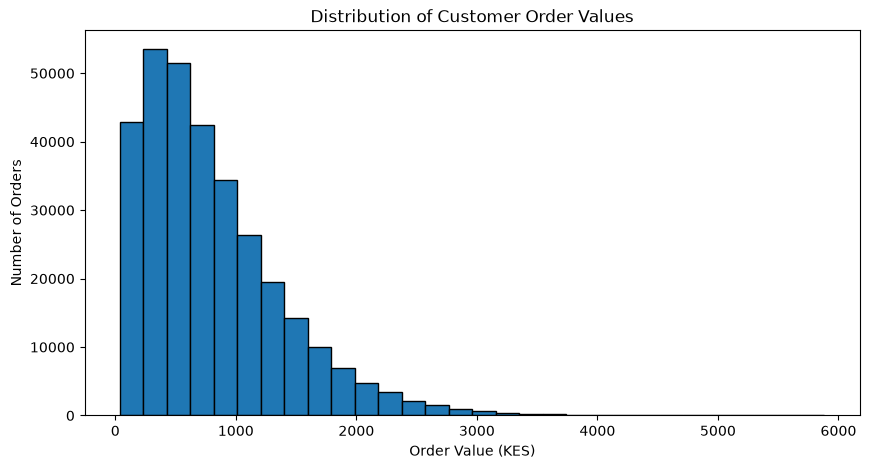

In [17]:
# Distribution of customer order values

plt.figure(figsize=(10, 5))

plt.hist(orders["net_amount_kes"], bins=30, edgecolor="black")

plt.title("Distribution of Customer Order Values")
plt.xlabel("Order Value (KES)")
plt.ylabel("Number of Orders")

plt.show()

From the chart above, we can see that most customer orders are below KES 1,500, with the highest concentration around KES 300–600. The distribution is right-skewed, indicating that high-value orders are less frequent. This suggests that smaller purchases make up a large share of the retailer's transactions.

## 3.3 Monthly Sales Trends

In [18]:
# Calculate total revenue for each month
monthly_sales = orders.groupby("year_month")["net_amount_kes"].sum()

# Display the first five months
monthly_sales.head()

year_month
2024-01    5369427.51
2024-02    4814826.33
2024-03    5467045.63
2024-04    5114096.60
2024-05    5408936.38
Name: net_amount_kes, dtype: float64

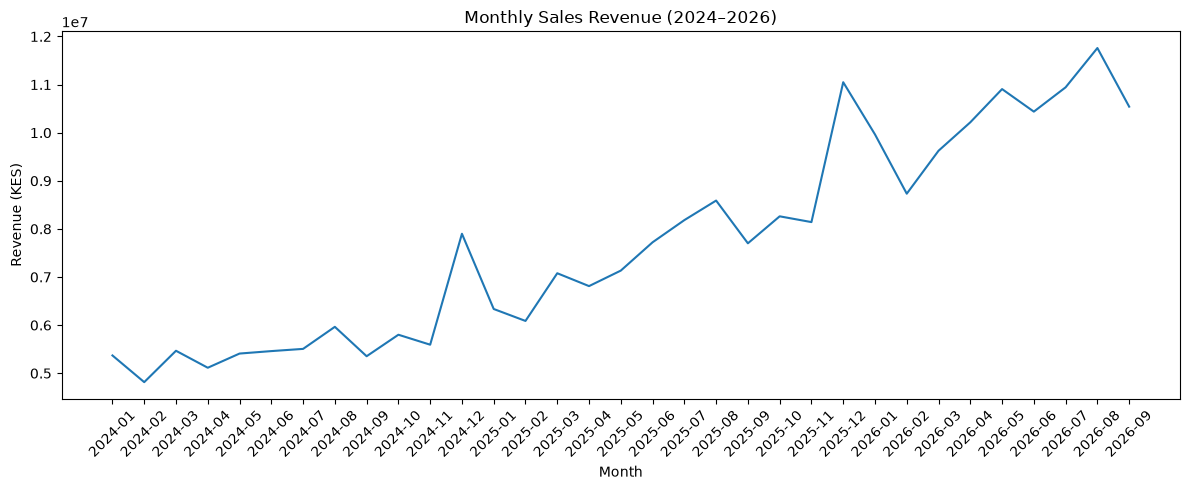

In [19]:
# Plot monthly sales trends
plt.figure(figsize=(12, 5))

plt.plot(monthly_sales.index, monthly_sales.values)

plt.title("Monthly Sales Revenue (2024–2026)")
plt.xlabel("Month")
plt.ylabel("Revenue (KES)")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Monthly sales revenue generally increased between 2024 and 2026, although there were fluctuations. December recorded noticeable sales increases in both 2024 and 2025, suggesting possible seasonal patterns.

## 3.4 Sales Seasonality

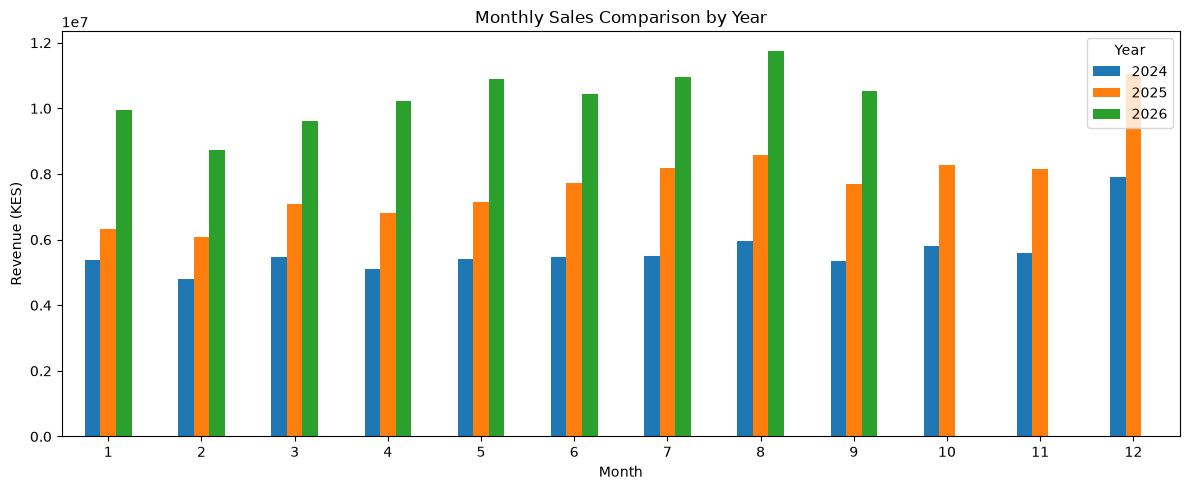

In [20]:
# Calculate monthly sales for each year
seasonal_sales = orders.groupby(["month", "year"])["net_amount_kes"].sum().unstack()

# Plot seasonal sales
seasonal_sales.plot(kind="bar", figsize=(12, 5))

plt.title("Monthly Sales Comparison by Year")
plt.xlabel("Month")
plt.ylabel("Revenue (KES)")
plt.legend(title="Year")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

December recorded the highest monthly sales in both 2024 and 2025, suggesting increased demand toward the end of the year. February had relatively lower sales.

## 3.5 Store and County Performance

### 3.5.1 Revenue by Store

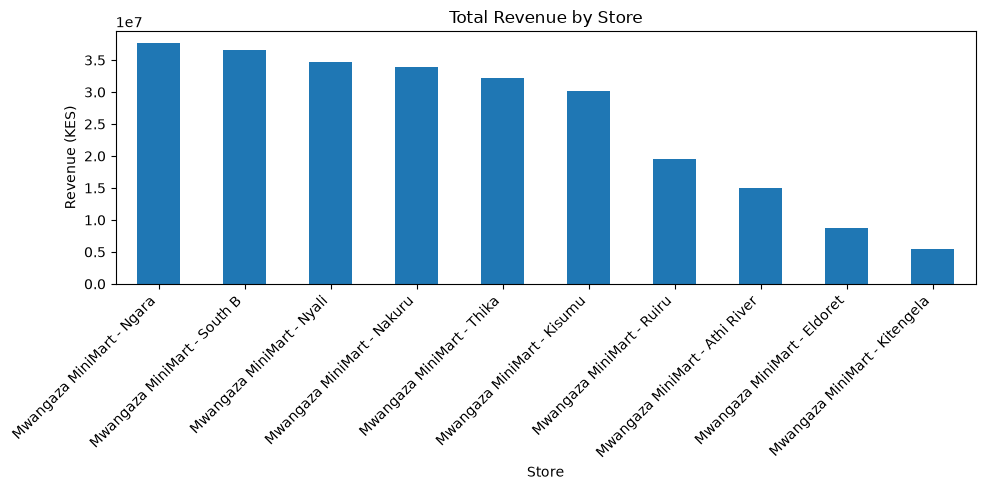

In [21]:
# Combine orders with store information
store_sales = orders.merge(stores, on="store_id")

# Calculate revenue by store
store_revenue = store_sales.groupby("store_name")["net_amount_kes"].sum()

# Sort from highest to lowest
store_revenue = store_revenue.sort_values(ascending=False)

# Plot
store_revenue.plot(kind="bar", figsize=(10, 5))

plt.title("Total Revenue by Store")
plt.xlabel("Store")
plt.ylabel("Revenue (KES)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

We can see that Ngara and South B recorded the highest total sales revenue, while Kitengela and Eldoret recorded the lowest.

### 3.5.2. Revenue by County

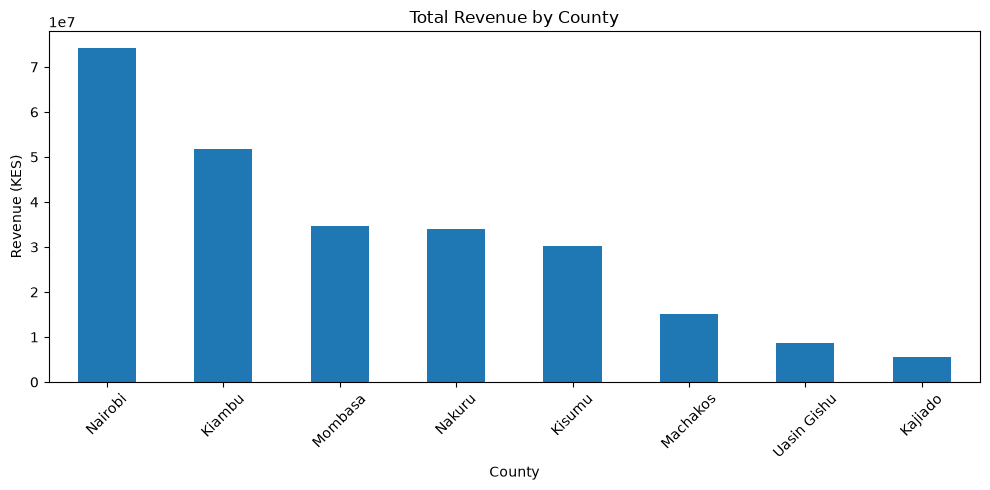

In [22]:
# Calculate revenue by county
county_revenue = store_sales.groupby("county")["net_amount_kes"].sum()

# Sort from highest to lowest
county_revenue = county_revenue.sort_values(ascending=False)

# Plot
county_revenue.plot(kind="bar", figsize=(10, 5))

plt.title("Total Revenue by County")
plt.xlabel("County")
plt.ylabel("Revenue (KES)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Nairobi generated the highest sales revenue, followed by Kiambu, maybe because of more and longer running stores, while Kajiado recorded the lowest.

### 3.5.3 Checking County Population Data

In [23]:
# Combine county revenue with population data
county_summary = county_revenue.reset_index().merge(
    county_population[["county", "population_2019"]],
    on="county"
)

county_summary

,county,net_amount_kes,population_2019
0,Nairobi,74205231.33,4397073
1,Kiambu,51681615.54,2417735
2,Mombasa,34666638.85,1208333
3,Nakuru,33996980.81,2162202
4,Kisumu,30189411.56,1155574
5,Machakos,15001793.20,1421932
6,Uasin Gishu,8742289.14,1163186
7,Kajiado,5487337.86,1117840


## 3.6 Product Category Performance

In [24]:
# Combine order items with product information
product_sales = order_items.merge(products, on="product_id")

# Calculate revenue by product category
category_revenue = product_sales.groupby("category")["line_net_kes"].sum()

# Sort from highest to lowest
category_revenue = category_revenue.sort_values(ascending=False)

category_revenue

category
Staples            65077458.51
Beverages          29782286.05
Dairy & Eggs       27700728.10
Fresh Produce      26981342.32
Meat & Fish        22016931.99
Baby Care          21512230.73
Bakery & Snacks    21223603.22
Household          16612444.11
Personal Care      15941734.62
Stationery          7122538.64
Name: line_net_kes, dtype: float64

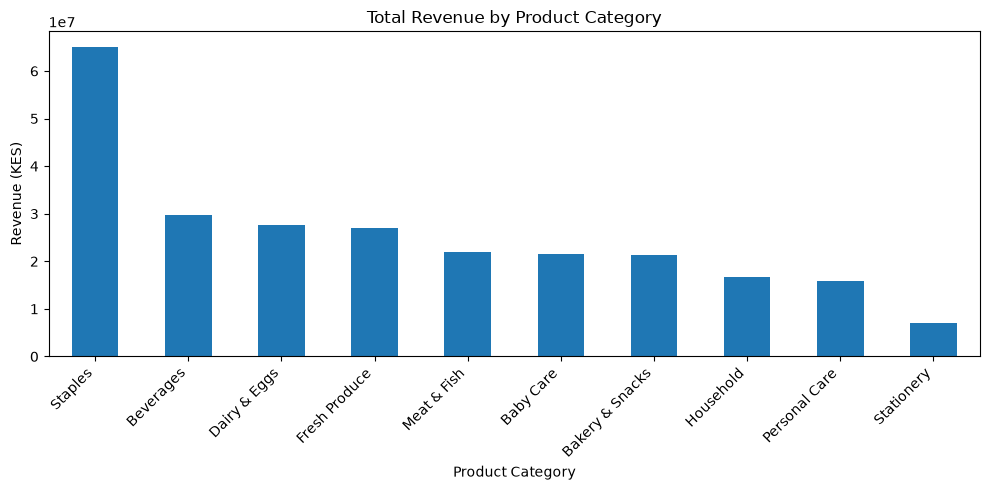

In [25]:
# Plot revenue by product category
category_revenue.plot(kind="bar", figsize=(10, 5))

plt.title("Total Revenue by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Revenue (KES)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

Staples generated the highest revenue, followed by Beverages and Dairy & Eggs. Stationery contributed the least. This suggests that essential food products are major revenue drivers for the retailer.

## 3.7 Customer Segmentation

age_band
45-54      807.195201
18-24      803.943965
35-44      803.285498
25-34      802.540740
Unknown    796.341712
55+        792.041970
Name: net_amount_kes, dtype: float64


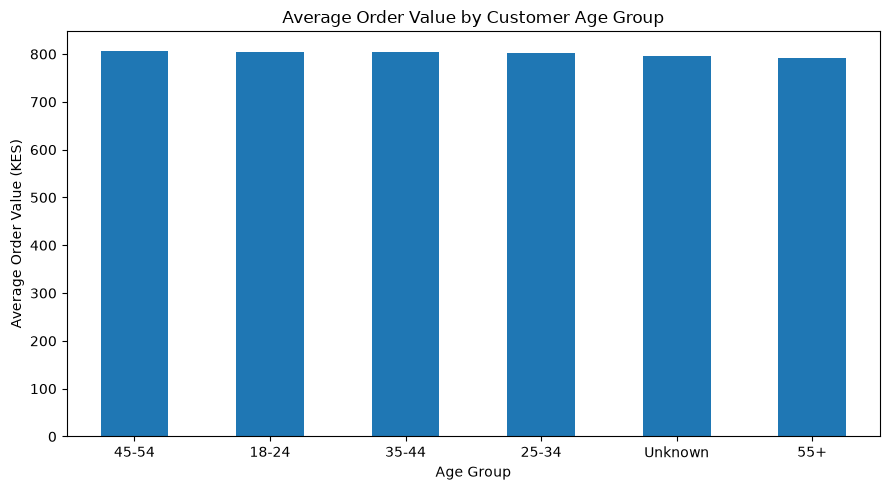

In [26]:
# Combine orders with customer information
customer_sales = orders.merge(customers, on="customer_id", how="inner")

# Calculate average order value by age group
age_spending = customer_sales.groupby("age_band")["net_amount_kes"].mean()

# Sort from highest to lowest
age_spending = age_spending.sort_values(ascending=False)

print(age_spending)

# Plot average order value by age group
age_spending.plot(kind="bar", figsize=(9, 5))

plt.title("Average Order Value by Customer Age Group")
plt.xlabel("Age Group")
plt.ylabel("Average Order Value (KES)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Average order values are relatively similar across customer age groups, ranging from approximately KES 792 to KES 807. This suggests that age may not be a major factor in determining how much registered customers spend per order.

## 3.8 Five Key Findings


1. **Sales Growth:** Monthly revenue generally increased between 2024 and 2026, although some growth may be linked to new store openings.

2. **Seasonality:** December recorded the highest monthly revenue in both 2024 and 2025, suggesting stronger year-end demand.

3. **Store and County Performance:** Ngara and South B generated the highest store revenues. Nairobi led county sales with approximately KES 74.2 million, while Kajiado recorded the lowest.

4. **Product Performance:** Staples generated the most revenue at approximately KES 65.1 million, making them the leading product category.

5. **Customer Behaviour:** Average order values differed very little across age groups, ranging from approximately KES 792 to KES 807.
